# Number theory 3: Algebraic factoring

*Learning path: number theory, part 3 of 7.* [Index](README.md) · Previous: [Prime factoring](02-prime-factoring.ipynb) · Next: [Modular arithmetic](04-modular-arithmetic.ipynb)

In the last lesson, Pollard's rho needed about $\sqrt p$ steps to find a prime factor $p$, so a factor with 20 digits
was already out of reach. Yet Galileo takes a number with 301 digits and pulls out prime factors with 33 and 72
digits in about a second. This lesson explains the trick: **factor the formula before you plug in the numbers**. You
will learn

* why $x^n - 1$ and $x^n + 1$ always split, into **cyclotomic polynomials**,
* how that cuts numbers like $10^{300} + 1$ into smaller pieces, and which primes can hide in each piece,
* **Sophie Germain's identity** $a^4 + 4b^4 = (a^2 - 2ab + 2b^2)(a^2 + 2ab + 2b^2)$,
* the surprise splits found by Aurifeuille and Lucas in the 1870s, which the Cunningham Project still uses today,
* how to **hunt for new identities** yourself with `factorsearch`.

## 1. A mystery

$10^{300} + 1$ is a 1 followed by 299 zeros and a final 1. `digits(n)` counts the decimal digits of a whole number:

In [1]:
N = 10^300 + 1;
digits(N)
factor(N)

301

> `digits`: The number of decimal digits of the whole number n.

[                                                                                                                                                          73, 1;
                                                                                                                                                          137, 1;
                                                                                                                                                          401, 1;
                                                                                                                                                         1201, 1;
                                                                                                                                                         1601, 1;
                                                                                                                                                        32401, 1;
                            

> 1000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000001 = 73 * 137 * 401 * 1201 * 1601 * 32401 * 1676321 * 99990001 * 5964848081 * 100009999999899989999000000010001 * 129694419029057750551385771184564274499075700947656757821537291527196801 * C156
>
> C156 = 308632449615752600231474337211814450171291009536742693126755038424739977161198725347983086941761056726644239375327921977716737137742662263513471806425727601 (composite: no factor found in reasonable time)
>
> `factor` of a whole number gives one row per prime: the prime and its exponent. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time; its row holds the whole composite number.

The answer lists eleven primes, and then `C156`: a part with 156 digits that did not split within a second. The line
below the product gives it in full and says honestly that it is composite: we know it has factors, because it fails
the Miller–Rabin test of lesson 2, but we did not find them.

Two things are strange. The primes $100009999999899989999000000010001$ (33 digits) and the 72-digit one are far too
big for rho, which would need about $10^{16}$ and $10^{36}$ steps. And the small ones, $73 \cdot 137 = 10001$, look
familiar:

In [2]:
73*137
mod(N, 10001)

10001
0

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

$10001 = 10^4 + 1$ divides $10^{300} + 1$, with remainder 0. Why? Put $x = 10^4$. Then $10^{300} = x^{75}$, and
$x^{75} + 1$ has the factor $x + 1$ because 75 is odd. Galileo's `factor` also works on polynomials:

In [3]:
factor(x^3 + 1)
factor(x^5 + 1)

(x+1)*(x^2-x+1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

(x+1)*(x^4-x^3+x^2-x+1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

In general $x^m + 1 = (x + 1)(x^{m-1} - x^{m-2} + \cdots - x + 1)$ for every odd $m$: put $x = -1$ and the left side is
$(-1)^m + 1 = 0$, so $x + 1$ is a factor. The same works for any $x = 10^d$ with $300/d$ odd, so $10^{300} + 1$ is
divisible by $10^4 + 1$, $10^{12} + 1$, $10^{20} + 1$, $10^{60} + 1$, $10^{100} + 1$ and $10^{300} + 1$ itself. Galileo
noticed that the number has the form $10^{300} + 1$, cut it into pieces along these lines, and factored each piece
separately. To see how the pieces fit together we need the polynomials behind them.

## 2. $x^n - 1$ and the cyclotomic polynomials

In [4]:
factor(x^12 - 1)

(x-1)*(x+1)*(x^2+1)*(x^2+x+1)*(x^2-x+1)*(x^4-x^2+1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

$x^{12} - 1$ splits into six pieces with small whole coefficients, and Galileo proves none of them splits further. Each
piece collects some of the roots of $x^{12} - 1$. Those roots are the **12th roots of unity**, the complex numbers
$$z_k = \cos\frac{2\pi k}{12} + i \sin\frac{2\pi k}{12}, \qquad k = 0, 1, \ldots, 11,$$
twelve points evenly spaced on the unit circle (the [complex numbers](../foundations/06-complex-numbers.ipynb) lesson of the foundations path has more). The
**order** of $z_k$ is the smallest $d \ge 1$ with $z_k^d = 1$; it is $12/\gcd(k, 12)$. The **cyclotomic polynomial**
$\Phi_d(x)$ ("circle dividing", from Greek) has as its roots exactly the roots of unity of order $d$:

$$\Phi_d(x) = \prod_{\text{order}(z) = d} (x - z), \qquad x^n - 1 = \prod_{d \mid n} \Phi_d(x).$$

The plot draws the twelve roots. Each colour is one cyclotomic factor $\Phi_d$, whose roots have order $d$: across is the real part
$\cos(2\pi k/12)$, up the imaginary part $\sin(2\pi k/12)$. `table(expr, k, [list])` makes one row per value in the
list, and `R(ks)` turns a list of $k$ values into rows of points:

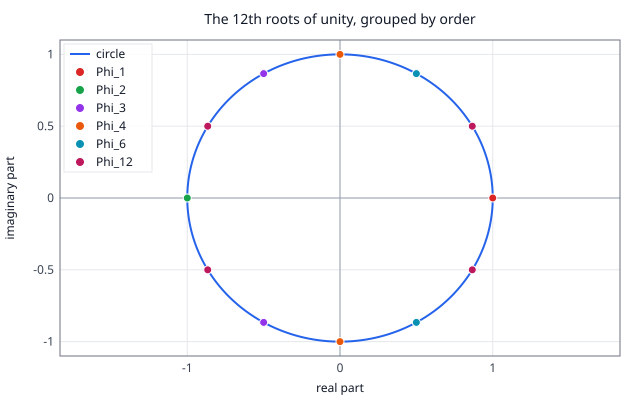

> `title`: A copy of plot p with a title or axis labels.

In [5]:
R(ks) := table([cos(2*pi*k/12), sin(2*pi*k/12)], k, ks);
pl = show(parametric(cos(t), sin(t), t, 0, 2*pi), scatter(R([0]), [re im]), scatter(R([6]), [re im]), scatter(R([4 8]), [re im]), scatter(R([3 9]), [re im]), scatter(R([2 10]), [re im]), scatter(R([1 5 7 11]), [re im]));
pl = legend(pl, "circle", "Phi_1", "Phi_2", "Phi_3", "Phi_4", "Phi_6", "Phi_12");
labels(title(pl, "The 12th roots of unity, grouped by order"), "real part", "imaginary part")

`cyclotomic(n)` gives $\Phi_n(x)$. Multiplying the six factors for the divisors $d = 1, 2, 3, 4, 6, 12$ of 12 gives
back $x^{12} - 1$:

In [6]:
table([n, cyclotomic(n)], n, 1, 12)
expand(cyclotomic(1)*cyclotomic(2)*cyclotomic(3)*cyclotomic(4)*cyclotomic(6)*cyclotomic(12))

[ 1,                                      x-1;
  2,                                      x+1;
  3,                                  x^2+x+1;
  4,                                    x^2+1;
  5,                          x^4+x^3+x^2+x+1;
  6,                                  x^2-x+1;
  7,                  x^6+x^5+x^4+x^3+x^2+x+1;
  8,                                    x^4+1;
  9,                                x^6+x^3+1;
 10,                          x^4-x^3+x^2-x+1;
 11, x^10+x^9+x^8+x^7+x^6+x^5+x^4+x^3+x^2+x+1;
 12,                                x^4-x^2+1]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

x^12-1

> `expand`: Multiplies out products and powers.

Three facts make these polynomials so useful:

* **Whole coefficients.** Although the roots are complex, $\Phi_n(x)$ has integer coefficients. That follows from
  $x^n - 1 = \prod_{d\mid n}\Phi_d(x)$ by dividing out the smaller ones in turn.
* **Irreducible.** $\Phi_n$ never splits into polynomials with whole coefficients. Gauss proved it for prime $n$ in
  1801; Kronecker proved it for every $n$ in 1854. So the factorization of $x^n - 1$ above is the final one.
* **Small coefficients, almost.** Up to $n = 104$ every coefficient is 0, 1 or $-1$. The first exception is
  $\Phi_{105}$, $105 = 3\cdot5\cdot7$, where $-2$ appears (Migotti, 1883). `coeff(p, x, k)` picks the coefficient of
  $x^k$:

In [7]:
coeff(cyclotomic(105), x, 7)
coeff(cyclotomic(105), x, 41)

-2

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

-2

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

And $x^n + 1$? Since $x^{2n} - 1 = (x^n - 1)(x^n + 1)$, the factors of $x^n + 1$ are the $\Phi_d$ with $d$ dividing $2n$
but not $n$. For $n = 300$ those are $d = 8, 24, 40, 120, 200, 600$:

In [8]:
factor(x^20 + 1)

(x^4+1)*(x^16-x^12+x^8-x^4+1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

## 3. Back to numbers: the algebraic pieces

Putting $x = 10$ into $x^{300} + 1 = \Phi_8\,\Phi_{24}\,\Phi_{40}\,\Phi_{120}\,\Phi_{200}\,\Phi_{600}$ cuts the 301-digit
number into six pieces $\Phi_d(10)$. `algfactor(n)` shows these pieces, one row each, with their size and how far each
one factors:

In [9]:
algfactor(10^300 + 1)

[73, 137, 401, 1201, 1601, 32401, 1676321, 99990001, 5964848081, 100009999999899989999000000010001, 129694419029057750551385771184564274499075700947656757821537291527196801, 308632449615752600231474337211814450171291009536742693126755038424739977161198725347983086941761056726644239375327921977716737137742662263513471806425727601]

> $$10^{300} + 1$$ splits algebraically into 6 pieces:
>
> | piece | digits | factors |
> |---|---|---|
> | $\Phi_{8}(10)$ | 5 | 73 · 137 |
> | $\Phi_{24}(10)$ | 8 | prime |
> | $\Phi_{40}(10)$ | 16 | 1676321 · 5964848081 |
> | $\Phi_{120}(10)$ | 33 | prime |
> | $\Phi_{200}(10)$ | 80 | 401 · 1201 · 1601 · 129694419029057750551385771184564274499075700947656757821537291527196801 |
> | $\Phi_{600}(10)$ | 161 | 32401 · **C156** (composite, no factor found) |
>
> 11 prime factors found; 1 composite part with 156 digits in all did not split in reasonable time.
>
> The value lists the factors found (primes, and any composite part left), smallest first; r[k] is piece k.

Now the mystery is solved. The 33-digit prime is a whole piece, $\Phi_{120}(10)$, so it never had to be *found*: the
algebra handed it over, and Miller–Rabin only had to check that it is prime. The piece $\Phi_{200}(10)$ has 80 digits;
after rho removes 401, 1201 and 1601 the rest, 72 digits, is again prime. Only $\Phi_{600}(10)$, with 161 digits,
keeps a composite part that nobody here can split.

### Which primes can hide in a piece?

Look at the primes and the piece they came from: $73 = 9\cdot 8 + 1$ and $137 = 17 \cdot 8 + 1$ in $\Phi_8(10)$;
$401 = 2\cdot 200 + 1$, $1201 = 6\cdot200 + 1$, $1601 = 8 \cdot 200 + 1$ in $\Phi_{200}(10)$:

In [10]:
mod([73 137], 8)
mod([401 1201 1601], 200)
mod(32401, 600)

[1, 1]

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

[1, 1, 1]

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

1

> `mod`: Remainder of a / b (with the sign of b), greatest common divisor, least common multiple.

Every one leaves remainder 1. This is a theorem: if a prime $p$ divides $\Phi_d(b)$ and does not divide $d$, then
$d$ is the order of $b$ mod $p$ (the smallest $k$ with $b^k \equiv 1$), and by Fermat's little theorem that order
divides $p - 1$, so $p \equiv 1 \pmod d$ (lesson 4 explains orders and Fermat's theorem). `multorder(b, p)` computes
the order:

In [11]:
multorder(10, 73)
multorder(10, 32401)

8

> `multorder`: The smallest k > 0 with a^k = 1 mod n, and the smallest primitive root mod n (a number whose powers give every unit).

600

> `multorder`: The smallest k > 0 with a^k = 1 mod n, and the smallest primitive root mod n (a number whose powers give every unit).

So the unknown factors of the 156-digit part all have the form $600k + 1$.

### Euler's 641

The oldest use of this fact is Euler's. Fermat believed that all the numbers $2^{2^m} + 1$ are prime; they are for
$m = 0, \ldots, 4$ (3, 5, 17, 257, 65537). In 1732 Euler showed that the next one, $2^{32} + 1$, is not. Since
$2^{32} + 1 = \Phi_{64}(2)$, every prime factor has the form $64k + 1$, and Euler only had to try those. The table has
$k$, the candidate $64k + 1$, whether it is prime, and the remainder of $2^{32} + 1$ divided by it:

In [12]:
F = 2^32 + 1;
table([k, 64*k + 1, isprime(64*k + 1), mod(F, 64*k + 1)], k, 1, 10)
factor(F)

[ 1,  65, false,  62;
  2, 129, false,  17;
  3, 193,  true, 109;
  4, 257,  true,   2;
  5, 321, false, 137;
  6, 385, false,  82;
  7, 449,  true, 325;
  8, 513, false, 482;
  9, 577,  true, 288;
 10, 641,  true,   0]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

[    641, 1;
 6700417, 1]

> 4294967297 = 641 * 6700417
>
> `factor` of a whole number gives one row per prime: the prime and its exponent. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time; its row holds the whole composite number.

Among the first ten candidates only five are prime (193, 257, 449, 577, 641), and the fifth one, $641 = 64\cdot10 + 1$,
divides. Plain trial division would have tried about 115 primes before reaching 641.

### Does the form speed up big factorizations?

It helps trial division a lot (only one number in $d$ is a candidate), but trial division only reaches small factors.
For the methods that reach large factors, the gain is smaller than you might hope:

* **Pollard's $p - 1$** (lesson 2) needs $p - 1$ to be smooth. Knowing that $d$ divides $p - 1$ gives $d$ for free.
  Galileo now does that for every algebraic piece. It only matters when $d$ has a prime factor too big for
  $p - 1$'s search, since small ones like $600 = 2^3\cdot3\cdot5^2$ are included anyway.
* **Pollard's rho** can walk with $x \to x^d + c$ instead of $x^2 + 1$. Modulo $p$ the values $x^d$ take only
  $(p - 1)/d$ different values, so the repeat comes about $\sqrt d$ times sooner. But each step now costs about
  $\log_2 d$ multiplications instead of one. For $d = 600$ that is a gain of $\sqrt{600} \approx 24$ against a cost of
  about 13: measured in Galileo it was no faster at all. Brent and Pollard used this walk, with $x^{1024} + 1$, to
  split $2^{256} + 1$ in 1981, where $d = 1024$ makes each step 10 squarings and saves a factor 32.
* For a cryptographic $p \cdot q$ there is no form to use. Its primes are random; the only pattern every prime above 3
  shares is $6k \pm 1$, which just says "not divisible by 2 or 3" and saves a constant factor. Key generators avoid
  primes with any special structure for exactly this reason.

### How much does the algebra save?

The piece $\Phi_n(b)$ has degree $\varphi(n)$ (Euler's totient `totient(n)`: how many of $1, \ldots, n$ share no factor with $n$; lesson 4), so it has about $\varphi(n)/n$ times as many
digits as $b^n - 1$. The table compares, for $n = 2, \ldots, 120$, the digits of $2^n - 1$ with the digits of its
largest new piece $\Phi_n(2)$; the plot has $n$ across and the number of digits up:

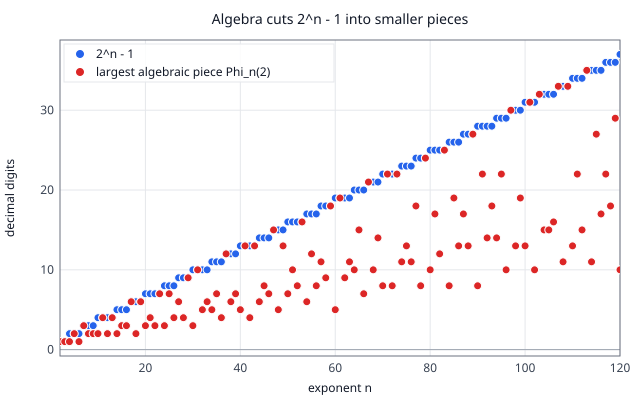

> `title`: A copy of plot p with a title or axis labels.

In [13]:
T = table([n, digits(2^n - 1), digits(cyclotomic(n, 2))], n, 2, 120);
pl = show(scatter(T, [n a c], [n a]), scatter(T, [n a c], [n c]));
pl = legend(pl, "2^n - 1", "largest algebraic piece Phi_n(2)");
labels(title(pl, "Algebra cuts 2^n - 1 into smaller pieces"), "exponent n", "decimal digits")

For a prime $n$ the piece is the whole number ($\Phi_n(2) = 2^n - 1$ when $n$ is prime), so those points lie on the top
row and get no help. For $n$ with many small factors, like $n = 120$ ($\varphi = 32$), the hardest piece has only about a
quarter of the digits. Factoring difficulty grows faster than exponentially in the digits, so this is an enormous
saving.

## 4. Sophie Germain's identity

Sums of two squares $a^2 + b^2$ don't factor over the whole numbers. They do once you allow $i = \sqrt{-1}$:
`factor(p, field)` factors over a bigger number system, here the Gaussian numbers $u + v\,i$ (other choices are a
square root like `sqrt(2)`, or a prime $n$ to factor modulo $n$):

In [14]:
factor(a^2 + b^2)
factor(a^2 + b^2, i)
factor(x^4 + 1, sqrt(2))
factor(x^4 + 1, 17)

a^2+b^2

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

(a-i*b)*(a+i*b)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

(x^2-sqrt(2)*x+1)*(sqrt(2)*x+x^2+1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

(x+2)*(x+8)*(x+9)*(x+15)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

$x^4 + 1$ is irreducible over the whole numbers, splits into two quadratics once $\sqrt2$ is allowed, and into four
linear factors modulo 17 (because 17 is $8k + 1$: the roots of $\Phi_8$ exist mod $p$ exactly when $p \equiv 1 \pmod 8$,
the rule of section 3 again).

Back to the whole numbers. $a^4 + b^4$ does not factor there either. But one special sum of fourth powers does:

In [15]:
factor(a^4 + 4*b^4)

(a^2-2*a*b+2*b^2)*(a^2+2*a*b+2*b^2)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

Sophie Germain (1776–1831), who also proved a famous special case of Fermat's last theorem, used this identity. The
proof is Fermat's difference-of-squares trick from lesson 2: add and subtract $4a^2b^2$,

$$a^4 + 4b^4 = (a^2 + 2b^2)^2 - (2ab)^2 = (a^2 + 2b^2 - 2ab)(a^2 + 2b^2 + 2ab).$$

In [16]:
expand((a^2 + 2*b^2)^2 - (2*a*b)^2)

a^4+4*b^4

> `expand`: Multiplies out products and powers.

Two consequences you can check. First, $n^4 + 4$ is prime only for $n = 1$: with $b = 1$ it is $(n^2 - 2n + 2)(n^2 + 2n + 2)$,
and the first factor is bigger than 1 as soon as $n > 1$. Second, $n^4 + 4^n$ is never prime for $n > 1$: for even $n$
it is even, and for odd $n$, $4^n = 4\cdot(2^{(n-1)/2})^4$, so Germain's identity applies with $a = n$. The table has
$n$, $n^4 + 4^n$, whether it is prime, and how many different primes divide it (the number of rows of its `factor`):

In [17]:
table([n, n^4 + 4^n, isprime(n^4 + 4^n), rows(factor(n^4 + 4^n))], n, 1, 9)

[1,      5,  true, 1;
 2,     32, false, 1;
 3,    145, false, 2;
 4,    512, false, 1;
 5,   1649, false, 2;
 6,   5392, false, 2;
 7,  18785, false, 3;
 8,  69632, false, 2;
 9, 268705, false, 3]

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

## 5. Surprise splits: Aurifeuille, Lucas and the Cunningham Project

In 1869 Fortuné Landry, the same man who split $2^{64} + 1$ in lesson 2, factored $2^{58} + 1$ by hand:

$$2^{58} + 1 = 5 \cdot 107\,367\,629 \cdot 536\,903\,681.$$

He wrote: "If we lose this result we shall miss patience and courage to repeat all calculations we have made." The
cyclotomic pieces don't explain it: $2^{58} + 1 = \Phi_4(2)\,\Phi_{116}(2) = 5 \cdot 57\,646\,075\,230\,342\,349$, and
the big piece $\Phi_{116}(2)$ still had to be cracked. Two years later, in 1871, Léon-François-Antoine Aurifeuille
saw that it splits *algebraically* after all. Put $a = 1$ and $b = 2^k$ in Sophie Germain's identity:

$$2^{4k+2} + 1 = 1 + 4\cdot(2^k)^4 = (2^{2k+1} - 2^{k+1} + 1)(2^{2k+1} + 2^{k+1} + 1).$$

For $k = 14$ that is $2^{58} + 1 = (2^{29} - 2^{15} + 1)(2^{29} + 2^{15} + 1)$, and Landry's hard work becomes one
line:

In [18]:
2^29 - 2^15 + 1
factor(2^29 - 2^15 + 1)
2^29 + 2^15 + 1
isprime(2^29 + 2^15 + 1)
algfactor(2^58 + 1)

536838145
[        5, 1;
 107367629, 1]

> 536838145 = 5 * 107367629
>
> `factor` of a whole number gives one row per prime: the prime and its exponent. Numbers like a^n ± b^n are first cut along their algebraic factors; then trial division, Pollard's rho and the elliptic curve method split the rest, and each factor is checked to be prime (Miller–Rabin). A part written C*k* (k digits) is composite but did not split in reasonable time; its row holds the whole composite number.

536903681
true

> `isprime`: Whether n is prime (Miller-Rabin: certain below 3.3e24, a 20-base probable-prime test above), the next prime after n and the last one before it.

[5, 107367629, 536903681]

> $$2^{58} + 1$$ splits algebraically into 3 pieces, 1 of them Aurifeuillean pairs $L \cdot M$:
>
> | piece | digits | factors |
> |---|---|---|
> | $\Phi_{4}(2)$ | 1 | prime |
> | $L_{116}(2)$ | 9 | prime |
> | $M_{116}(2)$ | 9 | prime |
>
> All 3 prime factors found.
>
> The value lists the factors found (primes, and any composite part left), smallest first; r[k] is piece k.

The first half is $5 \cdot 107\,367\,629$ (the 5 is the small cyclotomic piece $\Phi_4(2)$), the second half is prime.
`algfactor` shows three pieces: $\Phi_4(2) = 5$ and the two halves of $\Phi_{116}(2)$, called $L$ and $M$ as in the
factor tables.

### Where do the extra splits come from?

The cyclotomic polynomial $\Phi_n(x)$ itself never splits. But the number $2$ is $2\cdot 1^2$, and if we put
$x = 2y^2$ into $\Phi_n$, the new polynomial in $y$ sometimes does split. `cyclotomic(n, v)` puts $v$ in place of $x$;
for $n = 4$:

In [19]:
cyclotomic(4, 2*y^2)
factor(cyclotomic(4, 2*y^2))

4*y^4+1

> `cyclotomic`: The cyclotomic polynomial Phi_n(x): the product of x - z over the primitive n-th roots of unity z.

(2*y^2-2*y+1)*(2*y^2+2*y+1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

That is Aurifeuille's identity again (at $y = 2^k$, $4y^4 + 1 = 2^{4k+2} + 1$). Édouard Lucas found the general
pattern: for a squarefree base $s$ (no square divides it), $\Phi_n(s y^2)$ splits into two halves for the right $n$.
Here is a first hunt. `factorsearch(expr, k, a, b)` puts $k = a, a+1, \ldots, b$ into an expression, factors each
result over the whole numbers and lists the $k$ for which it splits. We search $n = 1, \ldots, 40$ for base 2:

In [20]:
factorsearch(cyclotomic(n, 2*y^2), n, 1, 40)

[                                                                                                                (2*y^2-2*y+1)*(2*y^2+2*y+1);
                                                                                         (4*y^4-4*y^3+2*y^2-2*y+1)*(4*y^4+4*y^3+2*y^2+2*y+1);
                                                             (16*y^8-16*y^7+8*y^6-4*y^4+2*y^2-2*y+1)*(16*y^8+16*y^7+8*y^6-4*y^4+2*y^2+2*y+1);
 (64*y^12-64*y^11+32*y^10-16*y^8+16*y^7-8*y^6+8*y^5-4*y^4+2*y^2-2*y+1)*(64*y^12+64*y^11+32*y^10-16*y^8-16*y^7-8*y^6-8*y^5-4*y^4+2*y^2+2*y+1);
                                                                               (64*y^12-32*y^9+8*y^6-4*y^3+1)*(64*y^12+32*y^9+8*y^6+4*y^3+1)]

> | n | polynomial | factors |
> |---|---|---|
> | 4 | $4 \, y^{4} + 1$ | $\left(2 \, y^{2} - 2 \, y + 1\right) \, \left(2 \, y^{2} + 2 \, y + 1\right)$ |
> | 12 | $16 \, y^{8} - 4 \, y^{4} + 1$ | $\left(4 \, y^{4} - 4 \, y^{3} + 2 \, y^{2} - 2 \, y + 1\right) \, \left(4 \, y^{4} + 4 \, y^{3} + 2 \, y^{2} + 2 \, y + 1\right)$ |
> | 20 | $256 \, y^{16} - 64 \, y^{12} + 16 \, y^{8} - 4 \, y^{4} + 1$ | $\left(16 \, y^{8} - 16 \, y^{7} + 8 \, y^{6} - 4 \, y^{4} + 2 \, y^{2} - 2 \, y + 1\right) \, \left(16 \, y^{8} + 16 \, y^{7} + 8 \, y^{6} - 4 \, y^{4} + 2 \, y^{2} + 2 \, y + 1\right)$ |
> | 28 | $4096 \, y^{24} - 1024 \, y^{20} + 256 \, y^{16} - 64 \, y^{12} + 16 \, y^{8} - 4 \, y^{4} + 1$ | $\left(64 \, y^{12} - 64 \, y^{11} + 32 \, y^{10} - 16 \, y^{8} + 16 \, y^{7} - 8 \, y^{6} + 8 \, y^{5} - 4 \, y^{4} + 2 \, y^{2} - 2 \, y + 1\right) \, \left(64 \, y^{12} + 64 \, y^{11} + 32 \, y^{10} - 16 \, y^{8} - 16 \, y^{7} - 8 \, y^{6} - 8 \, y^{5} - 4 \, y^{4} + 2 \, y^{2} + 2 \, y + 1\right)$ |
> | 36 | $4096 \, y^{24} - 64 \, y^{12} + 1$ | $\left(64 \, y^{12} - 32 \, y^{9} + 8 \, y^{6} - 4 \, y^{3} + 1\right) \, \left(64 \, y^{12} + 32 \, y^{9} + 8 \, y^{6} + 4 \, y^{3} + 1\right)$ |
>
> 5 of 40 values of n give a polynomial that factors over the integers.

The splits come at $n = 4, 12, 20, 28, 36$: exactly $n \equiv 4 \pmod 8$, the odd multiples of 4. The same search for
bases 3 and 5:

In [21]:
factorsearch(cyclotomic(n, 3*y^2), n, 1, 40)
factorsearch(cyclotomic(n, 5*y^2), n, 1, 40)

[                                                                                (3*y^2-3*y+1)*(3*y^2+3*y+1);
                                                                           (27*y^6-9*y^3+1)*(27*y^6+9*y^3+1);
 (81*y^8-81*y^7+54*y^6-27*y^5+9*y^4-9*y^3+6*y^2-3*y+1)*(81*y^8+81*y^7+54*y^6+27*y^5+9*y^4+9*y^3+6*y^2+3*y+1)]

> | n | polynomial | factors |
> |---|---|---|
> | 6 | $9 \, y^{4} - 3 \, y^{2} + 1$ | $\left(3 \, y^{2} - 3 \, y + 1\right) \, \left(3 \, y^{2} + 3 \, y + 1\right)$ |
> | 18 | $729 \, y^{12} - 27 \, y^{6} + 1$ | $\left(27 \, y^{6} - 9 \, y^{3} + 1\right) \, \left(27 \, y^{6} + 9 \, y^{3} + 1\right)$ |
> | 30 | $6561 \, y^{16} + 2187 \, y^{14} - 243 \, y^{10} - 81 \, y^{8} - 27 \, y^{6} + 3 \, y^{2} + 1$ | $\left(81 \, y^{8} - 81 \, y^{7} + 54 \, y^{6} - 27 \, y^{5} + 9 \, y^{4} - 9 \, y^{3} + 6 \, y^{2} - 3 \, y + 1\right) \, \left(81 \, y^{8} + 81 \, y^{7} + 54 \, y^{6} + 27 \, y^{5} + 9 \, y^{4} + 9 \, y^{3} + 6 \, y^{2} + 3 \, y + 1\right)$ |
>
> 3 of 40 values of n give a polynomial that factors over the integers.

[                                                                                                                                                                                                                                                                                                                                                                                                                                      (25*y^4-25*y^3+15*y^2-5*y+1)*(25*y^4+25*y^3+15*y^2+5*y+1);
                                                                                                                                                                                                                                                                                                                                                                       (625*y^8-625*y^7+250*y^6-125*y^5+75*y^4-25*y^3+10*y^2-5*y+1)*(625*y^8+625*y^7+250*y^6+125*y^5+75*y^4+25*y^3+10*y^2+5*y+1);
                                    

> | n | polynomial | factors |
> |---|---|---|
> | 5 | $625 \, y^{8} + 125 \, y^{6} + 25 \, y^{4} + 5 \, y^{2} + 1$ | $\left(25 \, y^{4} - 25 \, y^{3} + 15 \, y^{2} - 5 \, y + 1\right) \, \left(25 \, y^{4} + 25 \, y^{3} + 15 \, y^{2} + 5 \, y + 1\right)$ |
> | 15 | $390625 \, y^{16} - 78125 \, y^{14} + 3125 \, y^{10} - 625 \, y^{8} + 125 \, y^{6} - 5 \, y^{2} + 1$ | $\left(625 \, y^{8} - 625 \, y^{7} + 250 \, y^{6} - 125 \, y^{5} + 75 \, y^{4} - 25 \, y^{3} + 10 \, y^{2} - 5 \, y + 1\right) \, \left(625 \, y^{8} + 625 \, y^{7} + 250 \, y^{6} + 125 \, y^{5} + 75 \, y^{4} + 25 \, y^{3} + 10 \, y^{2} + 5 \, y + 1\right)$ |
> | 25 | $95367431640625 \, y^{40} + 30517578125 \, y^{30} + 9765625 \, y^{20} + 3125 \, y^{10} + 1$ | $\left(9765625 \, y^{20} - 390625 \, y^{15} + 9375 \, y^{10} - 125 \, y^{5} + 1\right) \, \left(9765625 \, y^{20} + 390625 \, y^{15} + 9375 \, y^{10} + 125 \, y^{5} + 1\right)$ |
> | 35 | $59604644775390625 \, y^{48} - 11920928955078125 \, y^{46} + 19073486328125 \, y^{38} - 3814697265625 \, y^{36} + 762939453125 \, y^{34} - 152587890625 \, y^{32} + 6103515625 \, y^{28} - 1220703125 \, y^{26} + 244140625 \, y^{24} - 48828125 \, y^{22} + 9765625 \, y^{20} - 390625 \, y^{16} + 78125 \, y^{14} - 15625 \, y^{12} + 3125 \, y^{10} - 5 \, y^{2} + 1$ | $\left(244140625 \, y^{24} - 244140625 \, y^{23} + 97656250 \, y^{22} - 19531250 \, y^{20} + 9765625 \, y^{19} - 1953125 \, y^{18} - 1953125 \, y^{17} + 1953125 \, y^{16} - 781250 \, y^{15} + 78125 \, y^{14} + 78125 \, y^{13} - 46875 \, y^{12} + 15625 \, y^{11} + 3125 \, y^{10} - 6250 \, y^{9} + 3125 \, y^{8} - 625 \, y^{7} - 125 \, y^{6} + 125 \, y^{5} - 50 \, y^{4} + 10 \, y^{2} - 5 \, y + 1\right) \, \left(244140625 \, y^{24} + 244140625 \, y^{23} + 97656250 \, y^{22} - 19531250 \, y^{20} - 9765625 \, y^{19} - 1953125 \, y^{18} + 1953125 \, y^{17} + 1953125 \, y^{16} + 781250 \, y^{15} + 78125 \, y^{14} - 78125 \, y^{13} - 46875 \, y^{12} - 15625 \, y^{11} + 3125 \, y^{10} + 6250 \, y^{9} + 3125 \, y^{8} + 625 \, y^{7} - 125 \, y^{6} - 125 \, y^{5} - 50 \, y^{4} + 10 \, y^{2} + 5 \, y + 1\right)$ |
>
> 4 of 40 values of n give a polynomial that factors over the integers.

Base 3 splits at $n = 6, 18, 30$, the odd multiples of 6; base 5 at $n = 5, 15, 25, 35$, the odd multiples of 5. The
general rule is: if $s \equiv 1 \pmod 4$, then $\Phi_n(s y^2)$ splits
when $n$ is an odd multiple of $s$; otherwise when $n$ is an odd multiple of $2s$. With $y = 1$ that splits $\Phi_n(s)$,
and so the numbers $s^m \pm 1$. Base 3 gives Lucas's identity

$$3^{6k+3} + 1 = (3^{2k+1} + 1)(3^{2k+1} - 3^{k+1} + 1)(3^{2k+1} + 3^{k+1} + 1),$$

and Galileo's `factor` uses these splits automatically, for any base. $3^{201} + 1$ has 96 digits; without the
algebra, rho gets stuck on a 58-digit part. With it, the five pieces all split:

In [22]:
digits(3^201 + 1)
algfactor(3^201 + 1)
algfactor(10^90 + 1)

96

> `digits`: The number of decimal digits of the whole number n.

[2, 2, 7, 32563, 275371, 1351123, 5390821, 5931946571197, 56755588835611, 301027886874675599533, 4299412981246169975118907]

> $$3^{201} + 1$$ splits algebraically into 5 pieces, 1 of them Aurifeuillean pairs $L \cdot M$:
>
> | piece | digits | factors |
> |---|---|---|
> | $\Phi_{2}(3)$ | 1 | 2<sup>2</sup> |
> | $\Phi_{6}(3)$ | 1 | prime |
> | $\Phi_{134}(3)$ | 32 | 5390821 · 4299412981246169975118907 |
> | $L_{402}(3)$ | 32 | 32563 · 1351123 · 301027886874675599533 |
> | $M_{402}(3)$ | 32 | 275371 · 5931946571197 · 56755588835611 |
>
> All 11 prime factors found.
>
> The value lists the factors found (primes, and any composite part left), smallest first; r[k] is piece k.

[61, 101, 181, 3541, 9901, 27961, 4188901, 39526741, 999999000001, 4999437541453012143121, 1105097795002994798105101]

> $$10^{90} + 1$$ splits algebraically into 9 pieces, 3 of them Aurifeuillean pairs $L \cdot M$:
>
> | piece | digits | factors |
> |---|---|---|
> | $\Phi_{4}(10)$ | 3 | prime |
> | $\Phi_{12}(10)$ | 4 | prime |
> | $L_{20}(10)$ | 4 | prime |
> | $M_{20}(10)$ | 5 | prime |
> | $\Phi_{36}(10)$ | 12 | prime |
> | $L_{60}(10)$ | 8 | prime |
> | $M_{60}(10)$ | 9 | 61 · 4188901 |
> | $L_{180}(10)$ | 24 | 181 · 4999437541453012143121 |
> | $M_{180}(10)$ | 25 | prime |
>
> All 11 prime factors found.
>
> The value lists the factors found (primes, and any composite part left), smallest first; r[k] is piece k.

### When you only have the number

Often you get just a long number $N$, not a formula. `algfactor(N)` then searches for a form itself: it tests whether
$N = a^k \pm 1$ for any base $a$ (by taking $k$-th roots of $N \mp 1$), whether $N = a^k \pm b^k$ for small $b$,
and whether $N$ divides some $b^k \pm 1$, which is how leftover parts in the factor tables look. That last test
computes $b, b^2, b^3, \ldots$ modulo $N$ and watches for $\pm1$. Here $N$ is $2^{1062} + 1$ with the factor 5
removed, written out as a 319-digit number:

In [23]:
N = (2^1062 + 1)/5;
algfactor(N)

[13, 37, 109, 709, 1181, 3541, 12037, 31153, 157649, 174877, 5397793, 5521693, 73505269, 94789873, 104399276341, 20847858316750657, 2995240087117909078735942093, 4542450849453080771964686220945142234000337275766302018662087067849561989954515659981106419499416786024929833139577807378751358179838861487568501928990554095655950392956352278123068768575114936693825949]

> This 319-digit number $N$ divides $$2^{1062} + 1$$ (1062 is the smallest such exponent for base 2), so it splits along the algebraic pieces of that number into 8 parts:
>
> | piece | digits | factors |
> |---|---|---|
> | $N \cap \Phi_{12}(2)$ | 2 | prime |
> | $N \cap L_{36}(2)$ | 2 | prime |
> | $N \cap M_{36}(2)$ | 3 | prime |
> | $N \cap L_{236}(2)$ | 18 | 1181 · 3541 · 157649 · 174877 |
> | $N \cap M_{236}(2)$ | 18 | 5521693 · 104399276341 |
> | $N \cap L_{708}(2)$ | 35 | 709 · 12037 · 2995240087117909078735942093 |
> | $N \cap M_{708}(2)$ | 36 | 31153 · 5397793 · 94789873 · 20847858316750657 |
> | $N \cap \Phi_{2124}(2)$ | 210 | 73505269 · **C202** (composite, no factor found) |
>
> 17 prime factors found; 1 composite part with 202 digits in all did not split in reasonable time.
>
> The value lists the factors found (primes, and any composite part left), smallest first; r[k] is piece k.

A second argument, `algfactor(N, effort)`, searches more bases and exponents and gives rho and $p - 1$ that many
times more work on each piece: `algfactor(N, 10)` takes about ten seconds.

### The Cunningham Project

In 1925 Allan Cunningham and Herbert Woodall published tables of factorizations of $b^n \pm 1$ for $b = 2, 3, 5, 6,
7, 10, 11, 12$. Continuing those tables became the **Cunningham Project**, one of the longest-running computations
in mathematics: the third edition of the tables, by John Brillhart, D. H. Lehmer, John Selfridge, Bryant Tuckerman and
Samuel Wagstaff, appeared in 2002, and Wagstaff keeps them up to date online. Volunteer projects (ECMNET, NFS@Home)
still work through its "most wanted" numbers. The tables split every number first into exactly the pieces you saw
here, with the Aurifeuillean halves listed separately as $L$ and $M$ (Landry's number appears as "2,58L" and
"2,58M"). Only then does the heavy machinery (the elliptic curve method, the number field sieve) start.

## 6. Hunting for identities

Are there more identities like Sophie Germain's, waiting to be found? Let's search. Which numbers $k$ make $x^4 + k$
factor? We try $k$ from $-50$ to $400$:

In [24]:
factorsearch(x^4 + k, k, -50, 400)

[          (x^2-7)*(x^2+7);
           (x^2-6)*(x^2+6);
           (x^2-5)*(x^2+5);
       (x-2)*(x+2)*(x^2+4);
           (x^2-3)*(x^2+3);
           (x^2-2)*(x^2+2);
       (x-1)*(x+1)*(x^2+1);
   (x^2-2*x+2)*(x^2+2*x+2);
   (x^2-4*x+8)*(x^2+4*x+8);
 (x^2-6*x+18)*(x^2+6*x+18)]

> | k | polynomial | factors |
> |---|---|---|
> | -49 | $x^{4} - 49$ | $\left(x^{2} - 7\right) \, \left(x^{2} + 7\right)$ |
> | -36 | $x^{4} - 36$ | $\left(x^{2} - 6\right) \, \left(x^{2} + 6\right)$ |
> | -25 | $x^{4} - 25$ | $\left(x^{2} - 5\right) \, \left(x^{2} + 5\right)$ |
> | -16 | $x^{4} - 16$ | $\left(x - 2\right) \, \left(x + 2\right) \, \left(x^{2} + 4\right)$ |
> | -9 | $x^{4} - 9$ | $\left(x^{2} - 3\right) \, \left(x^{2} + 3\right)$ |
> | -4 | $x^{4} - 4$ | $\left(x^{2} - 2\right) \, \left(x^{2} + 2\right)$ |
> | -1 | $x^{4} - 1$ | $\left(x - 1\right) \, \left(x + 1\right) \, \left(x^{2} + 1\right)$ |
> | 4 | $x^{4} + 4$ | $\left(x^{2} - 2 \, x + 2\right) \, \left(x^{2} + 2 \, x + 2\right)$ |
> | 64 | $x^{4} + 64$ | $\left(x^{2} - 4 \, x + 8\right) \, \left(x^{2} + 4 \, x + 8\right)$ |
> | 324 | $x^{4} + 324$ | $\left(x^{2} - 6 \, x + 18\right) \, \left(x^{2} + 6 \, x + 18\right)$ |
>
> 10 of 451 values of k give a polynomial that factors over the integers.

Two families appear. Negative squares, $x^4 - m^2 = (x^2 - m)(x^2 + m)$: the difference of squares. And
$k = 4, 64, 324 = 4\cdot1^4, 4\cdot2^4, 4\cdot3^4$: Sophie Germain's identity with $b = 1, 2, 3$. Nothing else, and
that is a theorem: $x^4 + k$ splits over the whole numbers only for these two families. Our search rediscovered both.

A second family: **trinomials** $x^n + x + 1$. The table has every $n$ from 2 to 30 for which it factors:

In [25]:
factorsearch(x^n + x + 1, n, 2, 30)

[                                                                            (x^2+x+1)*(x^3-x^2+1);
                                                                     (x^2+x+1)*(x^6-x^5+x^3-x^2+1);
                                                             (x^2+x+1)*(x^9-x^8+x^6-x^5+x^3-x^2+1);
                                                   (x^2+x+1)*(x^12-x^11+x^9-x^8+x^6-x^5+x^3-x^2+1);
                                         (x^2+x+1)*(x^15-x^14+x^12-x^11+x^9-x^8+x^6-x^5+x^3-x^2+1);
                               (x^2+x+1)*(x^18-x^17+x^15-x^14+x^12-x^11+x^9-x^8+x^6-x^5+x^3-x^2+1);
                     (x^2+x+1)*(x^21-x^20+x^18-x^17+x^15-x^14+x^12-x^11+x^9-x^8+x^6-x^5+x^3-x^2+1);
           (x^2+x+1)*(x^24-x^23+x^21-x^20+x^18-x^17+x^15-x^14+x^12-x^11+x^9-x^8+x^6-x^5+x^3-x^2+1);
 (x^2+x+1)*(x^27-x^26+x^24-x^23+x^21-x^20+x^18-x^17+x^15-x^14+x^12-x^11+x^9-x^8+x^6-x^5+x^3-x^2+1)]

> | n | polynomial | factors |
> |---|---|---|
> | 5 | $x^{5} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{3} - x^{2} + 1\right)$ |
> | 8 | $x^{8} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
> | 11 | $x^{11} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{9} - x^{8} + x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
> | 14 | $x^{14} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{12} - x^{11} + x^{9} - x^{8} + x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
> | 17 | $x^{17} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{15} - x^{14} + x^{12} - x^{11} + x^{9} - x^{8} + x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
> | 20 | $x^{20} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{18} - x^{17} + x^{15} - x^{14} + x^{12} - x^{11} + x^{9} - x^{8} + x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
> | 23 | $x^{23} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{21} - x^{20} + x^{18} - x^{17} + x^{15} - x^{14} + x^{12} - x^{11} + x^{9} - x^{8} + x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
> | 26 | $x^{26} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{24} - x^{23} + x^{21} - x^{20} + x^{18} - x^{17} + x^{15} - x^{14} + x^{12} - x^{11} + x^{9} - x^{8} + x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
> | 29 | $x^{29} + x + 1$ | $\left(x^{2} + x + 1\right) \, \left(x^{27} - x^{26} + x^{24} - x^{23} + x^{21} - x^{20} + x^{18} - x^{17} + x^{15} - x^{14} + x^{12} - x^{11} + x^{9} - x^{8} + x^{6} - x^{5} + x^{3} - x^{2} + 1\right)$ |
>
> 9 of 29 values of n give a polynomial that factors over the integers.

It splits exactly when $n \equiv 2 \pmod 3$, always with the factor $x^2 + x + 1 = \Phi_3(x)$. Can you see why?
The roots of $\Phi_3$ are the cube roots of unity $\omega$ (order 3), so $\omega^n$ only depends on $n$ mod 3, and
$\omega^n + \omega + 1 = 0$ exactly when $\omega^n = \omega^2$. Ernst Selmer proved in 1956 that the other factor never
splits further, and that $x^n - x - 1$ never factors at all:

In [26]:
factorsearch(x^n - x - 1, n, 2, 30)

>
> 0 of 29 values of n give a polynomial that factors over the integers.

Your turn. Some families to search (each takes a second or so):

* `factorsearch(x^4 + k*x^2 + 1, k, -20, 20)`: which $k$ work? (Try to write $x^4 + kx^2 + 1$ as a difference of
  squares.)
* `factorsearch(x^6 + k, k, -100, 1000)`: besides cubes and squares, is there a Germain-like family?
* `factorsearch(x^8 + k, k, 1, 2000)`, `factorsearch(x^n + x^2 + 1, n, 3, 40)`, `factorsearch(x^n + 2*x + 2, n, 2, 30)`.
* Homogeneous families work too: `factorsearch(a^4 + k*b^4, k, 1, 400)`.

**Be honest about the odds.** Factorizations of one-parameter families like these are very well studied, and
Aurifeuillean factorizations in particular are well understood (Andrew Granville and Peter Pleasants gave a modern
account of them in 2006). So a genuinely new identity is very unlikely. But every pattern you find has a reason, and finding
the reason, like the cube roots of unity for $x^n + x + 1$, is real mathematics. And if your search turns up something
you can't explain, check the literature, and then tell someone.

## Summary

* Factor the formula first: $x^n - 1 = \prod_{d\mid n}\Phi_d(x)$ and $x^n + 1 = \prod_{d \mid 2n,\ d\nmid n}\Phi_d(x)$, with
  irreducible **cyclotomic polynomials** $\Phi_d$ (`cyclotomic(d)`).
* So $b^n \pm 1$ splits into pieces $\Phi_d(b)$, each much smaller than the number. Primes in $\Phi_d(b)$ (not dividing
  $d$) are $\equiv 1 \pmod d$.
* **Sophie Germain:** $a^4 + 4b^4 = (a^2 - 2ab + 2b^2)(a^2 + 2ab + 2b^2)$; so $n^4 + 4$ and $n^4 + 4^n$ are composite
  for $n > 1$.
* **Aurifeuille and Lucas:** $\Phi_n(s y^2)$ splits for the right $n$, which splits $\Phi_n(s)$ into $L\cdot M$; for
  base 2, $2^{4k+2} + 1 = (2^{2k+1} - 2^{k+1} + 1)(2^{2k+1} + 2^{k+1} + 1)$.
* `factor` does all this automatically for numbers $a^n \pm b^n$, `algfactor` shows the pieces, and composite parts
  that don't split are shown as `C` and their number of digits.
* `factorsearch` hunts for factorizations in a family of polynomials.

**Try it:** Factor $2^{106} + 1$ with `algfactor`: which $k$ is it in Aurifeuille's formula? Compare `factor(2^120 - 1)`
with `factor(2^127 - 1)` and explain the difference with $\varphi(n)$. Find all $n \le 60$ for which `cyclotomic(n, 7*y^2)`
splits and check the rule of section 5.

Next: [Modular arithmetic](04-modular-arithmetic.ipynb), where orders and Fermat's little theorem, used above to locate
the primes in $\Phi_d(b)$, are explained properly.

## Sources

1. C. F. Gauss, *Disquisitiones Arithmeticae* (1801), section 7 (the cyclotomic polynomial for prime $n$ is irreducible).
2. L. Kronecker, "Mémoire sur les facteurs irréductibles de l'expression $x^n - 1$", *J. Math. Pures Appl.* 19 (1854) 177–192.
3. A. Migotti, "Zur Theorie der Kreisteilungsgleichung", *Sitzungsber. Akad. Wiss. Wien* 87 (1883) 7–14 (coefficients of $\Phi_n$; the $-2$ in $\Phi_{105}$).
4. F. Landry's factorization of $2^{58} + 1$ (1869) and Aurifeuille's identity (1871): ProofWiki, "Prime Decomposition of $2^{58}+1$ / Historical Note", and D. Wells, *Curious and Interesting Numbers*, 2nd ed., Penguin (1997).
5. "Aurifeuillean factorization", Wikipedia (Lucas's general form, and the table of $L$ and $M$ factors for bases up to 24).
6. A. J. C. Cunningham and H. J. Woodall, *Factorisation of $y^n \mp 1$, $y = 2, 3, 5, 6, 7, 10, 11, 12$ up to high powers $n$*, Hodgson, London (1925).
7. J. Brillhart, D. H. Lehmer, J. L. Selfridge, B. Tuckerman and S. S. Wagstaff Jr., *Factorizations of $b^n \pm 1$, $b = 2, 3, 5, 6, 7, 10, 11, 12$ up to high powers*, 3rd ed., Contemporary Mathematics 22, American Mathematical Society (2002); online tables at homes.cerias.purdue.edu/~ssw/cun.
8. E. S. Selmer, "On the irreducibility of certain trinomials", *Mathematica Scandinavica* 4 (1956) 287–302.
9. A. Granville and P. Pleasants, "Aurifeuillian factorization", *Mathematics of Computation* 75 (2006) 497–508.
10. R. P. Brent, "On computing factors of cyclotomic polynomials", *Mathematics of Computation* 61 (1993) 131–149.